In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

BASE = Path("..")                                  
RAW = BASE / "data" / "raw" / "hasil_survey.csv"
COLMAP = BASE / "config" / "column_map.json"
MIN_N = 5                                          

## **Memuat data dan ganti header pertanyaan mejadi kode**

In [2]:
norm = lambda s: " ".join(str(s).split()).lower()

cmap = json.loads(COLMAP.read_text(encoding="utf-8"))
raw = pd.read_csv(RAW, encoding="utf-8-sig")
raw = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]

tidak_ketemu = [str(c)[:60] for c in raw.columns if norm(c) not in cmap]
print("Kolom yang tidak ada di column_map.json:", tidak_ketemu)

df = raw.rename(columns={c: cmap[norm(c)] for c in raw.columns if norm(c) in cmap})

GRUP = {
    "WB":  [f"WB{i}" for i in range(1, 10)],
    "ACD": [f"ACD{i}" for i in range(1, 9)],
    "SOC": [f"SOC{i}" for i in range(1, 9)],
    "CAR": [f"CAR{i}" for i in range(1, 9)],
}
ITEMS = sum(GRUP.values(), [])
SCORES = [f"{k}_Score" for k in GRUP]
COMMENTS = ["WB_O1", "ACD_O1", "SOC_O1", "CAR_O1"]

print("Ukuran data mentah:", df.shape)
df[["Gender", "Semester", "Angkatan", "Departemen", "Prodi"] + ITEMS[:3]].head()

Kolom yang tidak ada di column_map.json: []
Ukuran data mentah: (149, 43)


,Gender,Semester,Angkatan,Departemen,Prodi,WB1,WB2,WB3
0,Laki-laki,Semester 5,2024,Departemen Teknik Elektro (DTE),S. Tr. Teknik Elektro Industri,4,4,3
1,Perempuan,Semester 3,2025,Departemen Teknologi Multimedia Kreatif (DTMK),D3 Teknologi Multimedia dan Broadcasting,1,4,1
2,Laki-laki,Semester 5,2024,Departemen Teknik Informatika dan Komputer (DTIK),S.Tr. Teknik Informatika,3,4,4
3,Laki-laki,Semester 5,2024,Departemen Teknik Informatika dan Komputer (DTIK),S.Tr. Sains Data Terapan,3,4,4
4,Laki-laki,Semester 5,2024,Departemen Teknik Informatika dan Komputer (DTIK),D3 Teknik Informatika,3,2,4


## **Cek kualitas Data**

In [3]:
num = df[ITEMS].apply(pd.to_numeric, errors="coerce")

bukan_angka = num.isna() & df[ITEMS].notna()          # misalnya isian "R"
print("Isian bukan angka:", int(bukan_angka.sum().sum()))
if bukan_angka.sum().sum() > 0:
    print(df[ITEMS].where(bukan_angka).stack().value_counts().to_string())

print("Isian kosong:", int(df[ITEMS].isna().sum().sum()))
di_luar = num.notna() & ~num.isin([1, 2, 3, 4, 5])
print("Isian di luar 1-5:", int(di_luar.sum().sum()))

Isian bukan angka: 0
Isian kosong: 0
Isian di luar 1-5: 0


In [4]:
bad = num.isna().any(axis=1) | ~num.isin([1, 2, 3, 4, 5]).all(axis=1)
print("Baris tidak valid:", int(bad.sum()), "dari", len(df))
print("Baris tidak valid (nomor baris di CSV, mulai 2):", (df.index[bad] + 2).tolist())

d = df.loc[~bad].copy()
d[ITEMS] = num.loc[~bad]

dup = d.duplicated(subset=["Timestamp"] + ITEMS)
print("Duplikat:", int(dup.sum()))
d = d.loc[~dup].reset_index(drop=True)

d["seragam"] = d[ITEMS].nunique(axis=1) == 1
print("Responden menjawab seragam:", int(d["seragam"].sum()), "| nilai:",
      d.loc[d["seragam"], ITEMS[0]].value_counts().to_dict())

print("\nResponden bersih:", len(d))

Baris tidak valid: 0 dari 149
Baris tidak valid (nomor baris di CSV, mulai 2): []
Duplikat: 0
Responden menjawab seragam: 7 | nilai: {5: 4, 2: 1, 4: 1, 3: 1}

Responden bersih: 149


In [5]:
# Skor per dimensi (rata-rata butir)
for k, cols in GRUP.items():
    d[f"{k}_Score"] = d[cols].mean(axis=1)

# Cek semester vs angkatan (perkiraan kasar, hanya untuk ditandai, bukan dibuang)
tahun = d["Timestamp"].astype(str).str.extract(r"(20\d{2})")[0].astype(float)
sem = pd.to_numeric(d["Semester"], errors="coerce")
ang = pd.to_numeric(d["Angkatan"], errors="coerce")
lo, hi = 2 * (tahun - ang), 2 * (tahun - ang) + 1
janggal = (sem < lo - 1) | (sem > hi + 1)
print("Semester tidak cocok dengan angkatan (perlu dicek):", int(janggal.sum()))
d.loc[janggal, ["Semester", "Angkatan", "Departemen"]]

Semester tidak cocok dengan angkatan (perlu dicek): 0


,Semester,Angkatan,Departemen


## **Demografi**

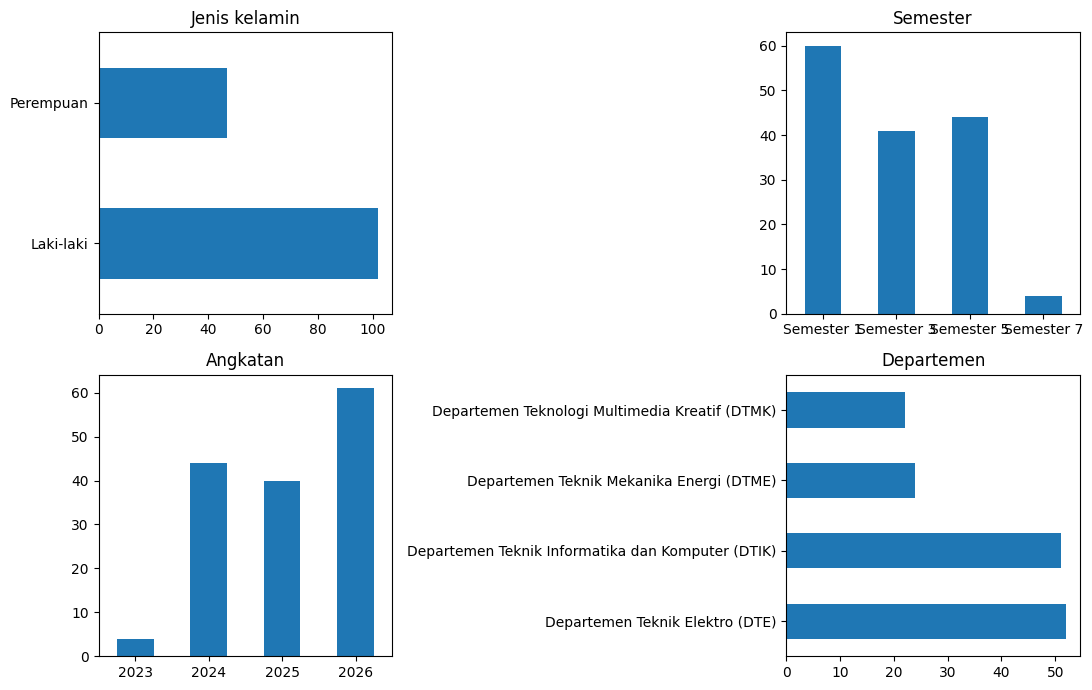

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
d["Gender"].value_counts().plot.barh(ax=ax[0, 0], title="Jenis kelamin")
d["Semester"].value_counts().sort_index().plot.bar(ax=ax[0, 1], title="Semester", rot=0)
d["Angkatan"].value_counts().sort_index().plot.bar(ax=ax[1, 0], title="Angkatan", rot=0)
d["Departemen"].value_counts().plot.barh(ax=ax[1, 1], title="Departemen")
for a in ax.ravel():
    a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

In [7]:
# Nama prodi tidak konsisten (titik dan spasi). Samakan dengan membuang semua simbol.
d["Prodi_norm"] = d["Prodi"].astype(str).map(lambda s: re.sub(r"[^a-z0-9]", "", s.lower()))
print("Variasi penulisan prodi:", d["Prodi"].nunique(), "-> setelah dinormalisasi:", d["Prodi_norm"].nunique())

prodi = d.groupby("Prodi_norm")["Prodi"].agg(lambda s: s.value_counts().index[0]).to_frame("nama_contoh")
prodi["n"] = d["Prodi_norm"].value_counts()
prodi.sort_values("n", ascending=False).reset_index(drop=True)

Variasi penulisan prodi: 18 -> setelah dinormalisasi: 18


,nama_contoh,n
0,S.Tr. Sains Data Terapan,27
1,S.Tr. Teknik Mekatronika,13
2,S.Tr. Teknologi Rekayasa Internet,12
3,S.Tr. Teknik Elektronika,11
4,S.Tr. Teknik Komputer,9
5,S.Tr. Teknologi Game,9
6,S. Tr. Teknik Elektro Industri,9
7,S.Tr. Sistem Pembangkit Energi,8
8,S.Tr. Teknik Telekomunikasi,7
9,D3 Teknik Elektro Industri,7


## **Distribusi jawaban**

In [8]:
ringkas = pd.DataFrame({
    "mean": d[ITEMS].mean(),
    "sd": d[ITEMS].std(),
    "%_jawab_4_5": (d[ITEMS] >= 4).mean() * 100,
    "%_jawab_1_2": (d[ITEMS] <= 2).mean() * 100,
    "%_jawab_5": (d[ITEMS] == 5).mean() * 100,
}).round(2)
ringkas.insert(0, "dimensi", [i.rstrip("0123456789") for i in ringkas.index])

print("5 butir dengan rata-rata terendah:")
print(ringkas.sort_values("mean").head(5).to_string())
print("\n5 butir dengan rata-rata tertinggi:")
print(ringkas.sort_values("mean", ascending=False).head(5).to_string())

5 butir dengan rata-rata terendah:
     dimensi  mean    sd  %_jawab_4_5  %_jawab_1_2  %_jawab_5
WB3       WB  2.84  1.20        28.86        42.95      11.41
ACD2     ACD  3.04  1.13        33.56        30.20      10.74
WB8       WB  3.07  1.34        38.93        36.24      19.46
CAR7     CAR  3.07  1.17        36.24        30.87      12.75
CAR4     CAR  3.15  1.09        36.24        26.85      12.75

5 butir dengan rata-rata tertinggi:
     dimensi  mean    sd  %_jawab_4_5  %_jawab_1_2  %_jawab_5
SOC2     SOC  4.13  0.84        79.19         3.36      37.58
SOC7     SOC  4.05  0.82        75.84         2.68      32.21
SOC1     SOC  4.03  0.85        73.83         3.36      32.89
SOC4     SOC  3.99  0.89        70.47         4.03      32.89
WB6       WB  3.96  1.11        69.80        12.75      41.61


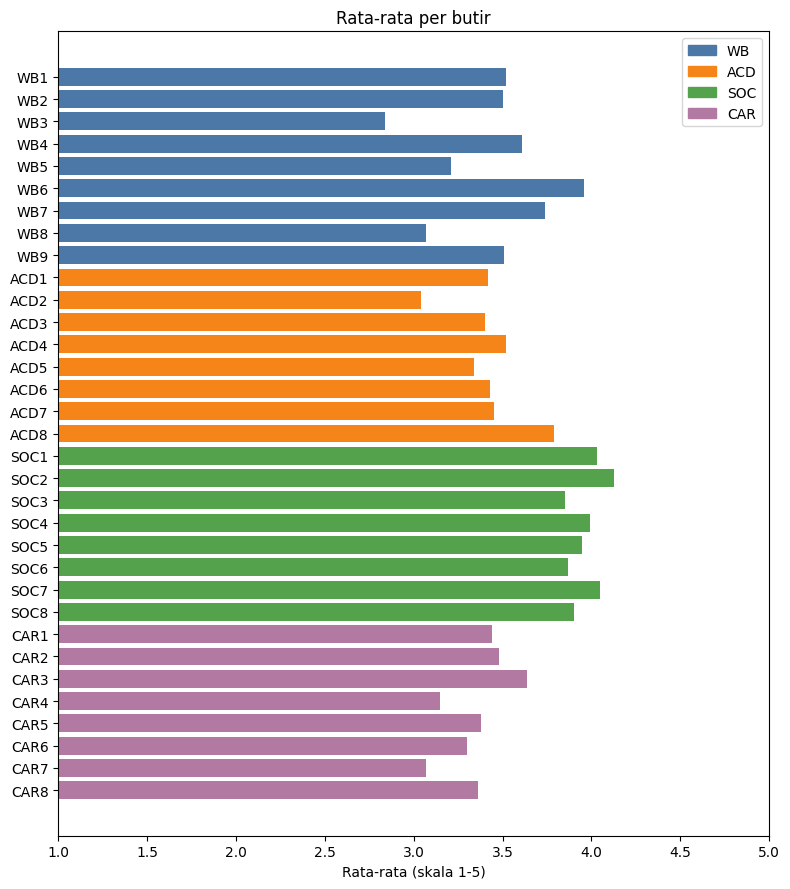

In [9]:
warna = {"WB": "#4C78A8", "ACD": "#F58518", "SOC": "#54A24B", "CAR": "#B279A2"}
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(ringkas.index[::-1], ringkas["mean"][::-1],
        color=[warna[g] for g in ringkas["dimensi"][::-1]])
ax.set_xlim(1, 5); ax.set_xlabel("Rata-rata (skala 1-5)")
ax.set_title("Rata-rata per butir")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in warna.values()], labels=list(warna))
plt.tight_layout(); plt.show()

## **Skor tiap dimensi**

In [10]:
print(d[SCORES].describe().round(2).to_string())

print("\nSkor tepat 5,00 / tepat 1,00:")
print(pd.DataFrame({
    "n_skor_5": (d[SCORES] == 5).sum(),
    "%_skor_5": ((d[SCORES] == 5).mean() * 100).round(1),
    "n_skor_1": (d[SCORES] == 1).sum(),
}).to_string())

       WB_Score  ACD_Score  SOC_Score  CAR_Score
count    149.00     149.00     149.00     149.00
mean       3.44       3.42       3.97       3.35
std        0.79       0.78       0.73       0.86
min        1.33       1.62       1.75       1.12
25%        2.89       3.00       3.50       2.88
50%        3.44       3.38       4.00       3.25
75%        4.00       4.00       4.50       4.00
max        5.00       5.00       5.00       5.00

Skor tepat 5,00 / tepat 1,00:
           n_skor_5  %_skor_5  n_skor_1
WB_Score          8       5.4         0
ACD_Score         7       4.7         0
SOC_Score        19      12.8         0
CAR_Score         6       4.0         0


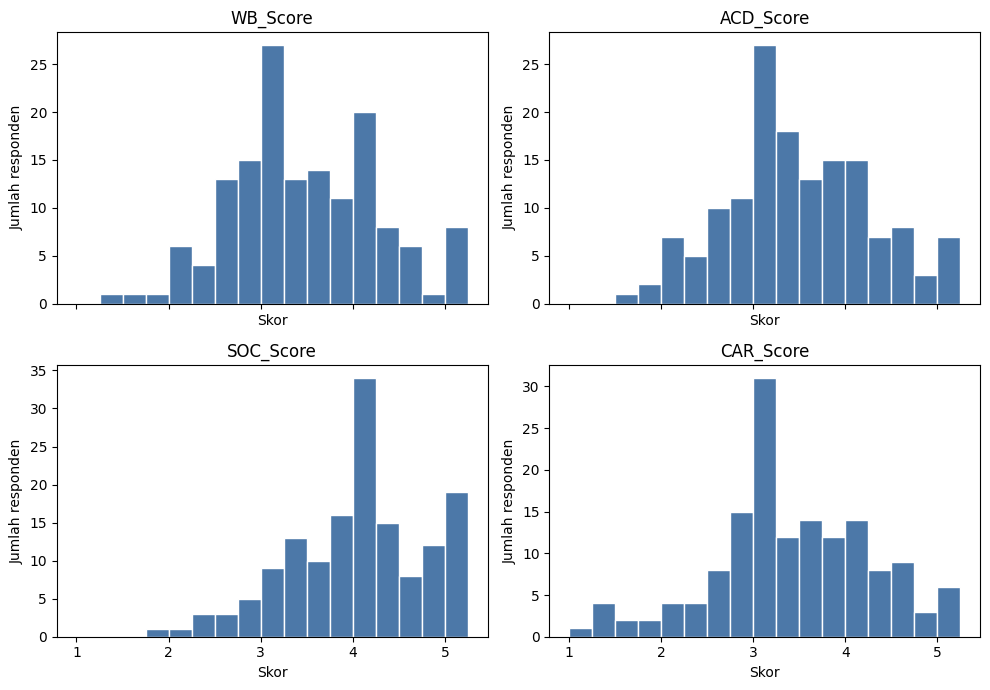

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for a, s in zip(ax.ravel(), SCORES):
    a.hist(d[s], bins=np.arange(1, 5.26, 0.25), color="#4C78A8", edgecolor="white")
    a.set_title(s); a.set_xlabel("Skor"); a.set_ylabel("Jumlah responden")
plt.tight_layout(); plt.show()

## **Korelasi antar skor**

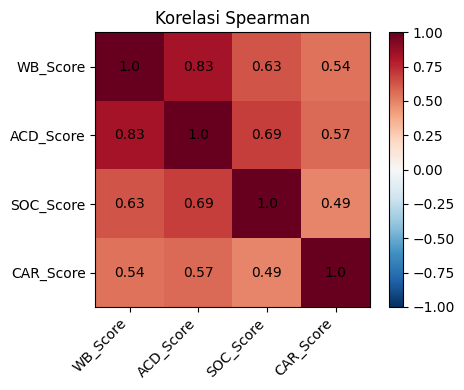

In [12]:
corr = d[SCORES].corr(method="spearman").round(2)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(4)); ax.set_xticklabels(SCORES, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(SCORES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center")
plt.colorbar(im); plt.title("Korelasi Spearman"); plt.tight_layout(); plt.show()

## **Perbandingan antar kelompok**

In [13]:
def per_kelompok(kolom):
    g = d.groupby(kolom)[SCORES].mean().round(2)
    g["n"] = d.groupby(kolom).size()
    g = g[g["n"] >= MIN_N]
    n_disembunyikan = d[kolom].nunique() - len(g)
    if n_disembunyikan:
        print(f"({n_disembunyikan} kelompok dengan n < {MIN_N} disembunyikan)")
    return g

per_kelompok("Gender")

,WB_Score,ACD_Score,SOC_Score,CAR_Score,n
Gender,,,,,
Laki-laki,3.47,3.44,4.0,3.46,102
Perempuan,3.37,3.39,3.9,3.12,47


In [14]:
per_kelompok("Departemen")

,WB_Score,ACD_Score,SOC_Score,CAR_Score,n
Departemen,,,,,
Departemen Teknik Elektro (DTE),3.28,3.25,3.94,3.38,52
Departemen Teknik Informatika dan Komputer (DTIK),3.45,3.49,4.03,3.33,51
Departemen Teknik Mekanika Energi (DTME),3.62,3.54,4.05,3.68,24
Departemen Teknologi Multimedia Kreatif (DTMK),3.60,3.56,3.82,2.99,22


In [15]:
per_kelompok("Angkatan")

(1 kelompok dengan n < 5 disembunyikan)


,WB_Score,ACD_Score,SOC_Score,CAR_Score,n
Angkatan,,,,,
2024,3.60,3.60,4.10,3.55,44
2025,2.99,3.09,3.64,2.98,40
2026,3.66,3.54,4.10,3.44,61
